# Customer Churn Prediction and Customer Segmentation System
### Machine Learning & Deep Learning Mini-Project

**Goal:** Predict whether a customer may leave a subscription service (churn) and discover customer groups using clustering.

**Experiments covered**
1. Environment setup and data preprocessing
2. SVM and Random Forest for binary/multiclass classification
3. Decision Tree classification
4A. SVM
4B. Random Forest
5. K-Means clustering and PCA
6. Feedforward Neural Network (FNN) and Convolutional Neural Network (CNN)
7. Generative Adversarial Network (GAN) demonstration
8. Grid Search and Cross-Validation
9. Flask REST API and Docker deployment

**Dataset note:** This notebook creates a reproducible *synthetic demonstration dataset* locally, so it can run without downloading customer information. Its scores are for demonstration only and are not evidence about real customers. For a real project, replace it with a properly licensed customer churn dataset and update the feature names.

**Suggested environment:** Python 3.10–3.12, Jupyter Notebook, scikit-learn, pandas, matplotlib, Flask, joblib. TensorFlow is optional for the FNN/CNN/GAN sections; those cells explain what to do if it is unavailable.


## 1. Set up the environment

In [1]:
# If a package is missing, run this in a notebook cell:
# %pip install numpy pandas matplotlib scikit-learn joblib flask

import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs("artifacts", exist_ok=True)
print("Environment ready.")


Environment ready.


## 2. Create/load and preprocess the dataset

In [2]:
# Synthetic example data: replace this block with pd.read_csv('your_churn.csv')
# Expected target column: Churn (0 = stays, 1 = leaves).
n = 1200
rng = np.random.default_rng(RANDOM_STATE)

tenure_months = rng.integers(1, 73, n)
monthly_charges = np.round(rng.normal(70, 22, n).clip(18, 150), 2)
support_calls = rng.poisson(2.0, n).clip(0, 10)
contract_type = rng.choice(["Month-to-month", "One-year", "Two-year"], n, p=[0.55, 0.28, 0.17])
internet_service = rng.choice(["Fiber", "DSL", "None"], n, p=[0.50, 0.35, 0.15])
payment_method = rng.choice(["Electronic", "Card", "Bank transfer"], n)
age = rng.integers(18, 81, n)
data = pd.DataFrame({
    "TenureMonths": tenure_months,
    "MonthlyCharges": monthly_charges,
    "SupportCalls": support_calls,
    "ContractType": contract_type,
    "InternetService": internet_service,
    "PaymentMethod": payment_method,
    "Age": age
})

logit = (
    1.25
    - 0.045 * data["TenureMonths"]
    + 0.025 * (data["MonthlyCharges"] - 65)
    + 0.30 * data["SupportCalls"]
    + 1.05 * (data["ContractType"] == "Month-to-month").astype(int)
    - 0.70 * (data["ContractType"] == "Two-year").astype(int)
    + 0.25 * (data["InternetService"] == "Fiber").astype(int)
)
probability = 1 / (1 + np.exp(-logit))
data["Churn"] = rng.binomial(1, probability)

# Introduce a few missing values for preprocessing demonstration.
for col in ["MonthlyCharges", "PaymentMethod"]:
    idx = rng.choice(data.index, size=12, replace=False)
    data.loc[idx, col] = np.nan

# Uncomment this to load your own dataset instead:
# data = pd.read_csv("customer_churn.csv")

print("Dataset shape:", data.shape)
display(data.head())
print("\nMissing values before cleaning:\n", data.isnull().sum())
print("\nTarget counts:\n", data["Churn"].value_counts())


Dataset shape: (1200, 8)


,TenureMonths,MonthlyCharges,SupportCalls,ContractType,InternetService,PaymentMethod,Age,Churn
0,7,97.45,3,Month-to-month,Fiber,Bank transfer,48,1
1,56,64.44,3,Month-to-month,None,Bank transfer,72,1
2,48,78.00,3,One-year,Fiber,Bank transfer,65,0
3,32,18.00,1,Two-year,Fiber,Card,31,1
4,32,44.56,0,Month-to-month,DSL,Bank transfer,71,1



Missing values before cleaning:
 TenureMonths        0
MonthlyCharges     12
SupportCalls        0
ContractType        0
InternetService     0
PaymentMethod      12
Age                 0
Churn               0
dtype: int64

Target counts:
 Churn
1    799
0    401
Name: count, dtype: int64


Processed feature count: 13
Training rows: 960 | Test rows: 240
Missing values after cleaning: 0


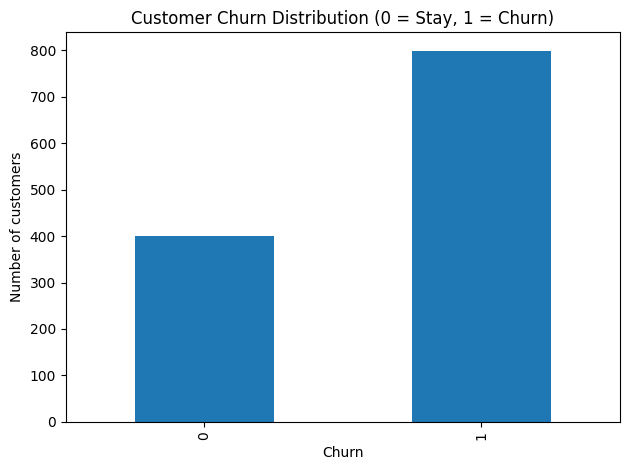

In [3]:
# Fill missing numerical values with the median and categorical values with the mode.
df = data.copy()
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes(exclude=np.number).columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# Convert categorical columns into numeric indicator columns.
X = pd.get_dummies(df.drop(columns=["Churn"]), drop_first=False, dtype=int)
y = df["Churn"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Processed feature count:", X.shape[1])
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Missing values after cleaning:", int(df.isnull().sum().sum()))

df["Churn"].value_counts().sort_index().plot(kind="bar")
plt.title("Customer Churn Distribution (0 = Stay, 1 = Churn)")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()


## 3. SVM and Random Forest: binary and multiclass classification

In [4]:
# Binary classification: 0 = stays, 1 = churns.
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))
])
rf_model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, class_weight="balanced")

models = {"SVM": svm_model, "Random Forest": rf_model}
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0)
    })
    print(f"\n{name} classification report")
    print(classification_report(y_test, pred, zero_division=0))
pd.DataFrame(results).set_index("Model")



SVM classification report
              precision    recall  f1-score   support

           0       0.62      0.39      0.48        80
           1       0.74      0.88      0.81       160

    accuracy                           0.72       240
   macro avg       0.68      0.63      0.64       240
weighted avg       0.70      0.72      0.70       240


Random Forest classification report
              precision    recall  f1-score   support

           0       0.69      0.51      0.59        80
           1       0.78      0.89      0.83       160

    accuracy                           0.76       240
   macro avg       0.74      0.70      0.71       240
weighted avg       0.75      0.76      0.75       240



,Accuracy,Precision,Recall,F1-score
Model,,,,
SVM,0.716667,0.742105,0.88125,0.805714
Random Forest,0.762500,0.784530,0.88750,0.832845


### Multiclass demonstration

In [5]:
# Create three customer-usage groups as a separate illustrative multiclass target.
# This is a derived teaching label, not the churn target.
usage_score = (
    df["TenureMonths"].rank(pct=True) +
    df["MonthlyCharges"].rank(pct=True) +
    df["SupportCalls"].rank(pct=True)
) / 3
usage_class = pd.qcut(usage_score, q=3, labels=["Low usage", "Medium usage", "High usage"])

Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X, usage_class, test_size=0.20, random_state=RANDOM_STATE, stratify=usage_class
)
multi_svm = Pipeline([("scaler", StandardScaler()), ("model", SVC())])
multi_rf = RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE)
for name, model in [("Multiclass SVM", multi_svm), ("Multiclass Random Forest", multi_rf)]:
    model.fit(Xm_train, ym_train)
    print(f"\n{name} accuracy: {accuracy_score(ym_test, model.predict(Xm_test)):.3f}")



Multiclass SVM accuracy: 0.854

Multiclass Random Forest accuracy: 0.842


## 4. Decision Tree classification

Decision Tree accuracy: 0.683
              precision    recall  f1-score   support

           0       0.52      0.72      0.60        80
           1       0.83      0.66      0.74       160

    accuracy                           0.68       240
   macro avg       0.67      0.69      0.67       240
weighted avg       0.72      0.68      0.69       240



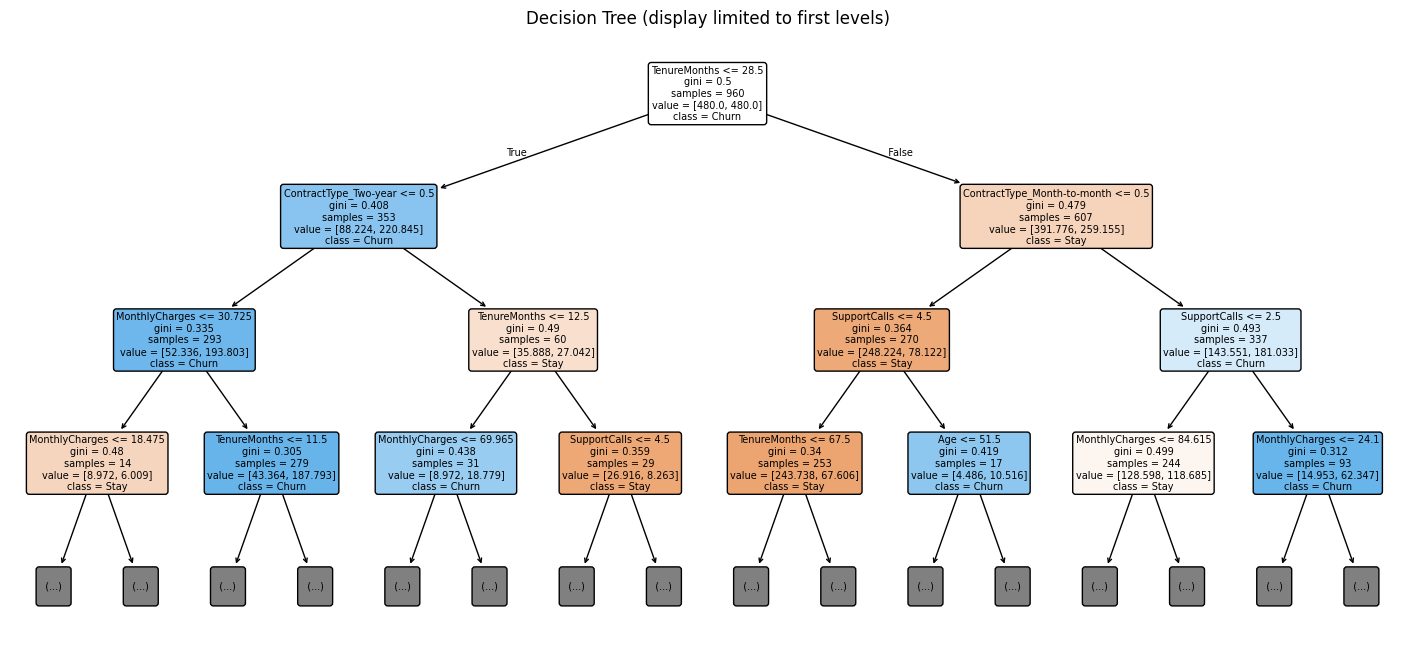

In [6]:
tree_model = DecisionTreeClassifier(
    max_depth=4, random_state=RANDOM_STATE, class_weight="balanced"
)
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)
print("Decision Tree accuracy:", round(accuracy_score(y_test, tree_pred), 3))
print(classification_report(y_test, tree_pred, zero_division=0))

plt.figure(figsize=(18, 8))
plot_tree(tree_model, feature_names=list(X.columns), class_names=["Stay", "Churn"],
          filled=True, rounded=True, max_depth=3, fontsize=7)
plt.title("Decision Tree (display limited to first levels)")
plt.show()


## 4A. Support Vector Machine (SVM)

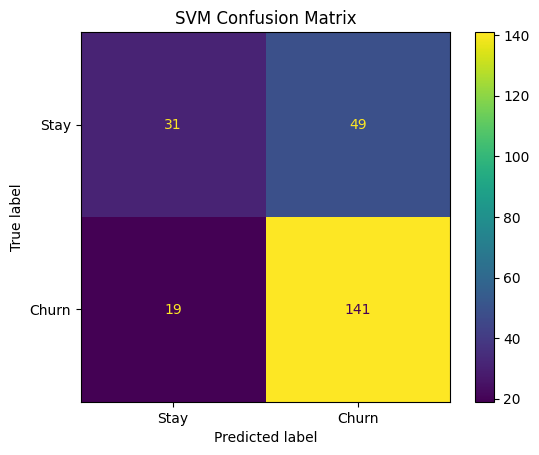

SVM F1-score: 0.806


In [7]:
# SVM uses scaled features because feature scales can affect the decision boundary.
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(
    y_test, svm_pred, display_labels=["Stay", "Churn"], cmap=None
)
plt.title("SVM Confusion Matrix")
plt.show()
print("SVM F1-score:", round(f1_score(y_test, svm_pred, zero_division=0), 3))


## 4B. Ensemble method: Random Forest

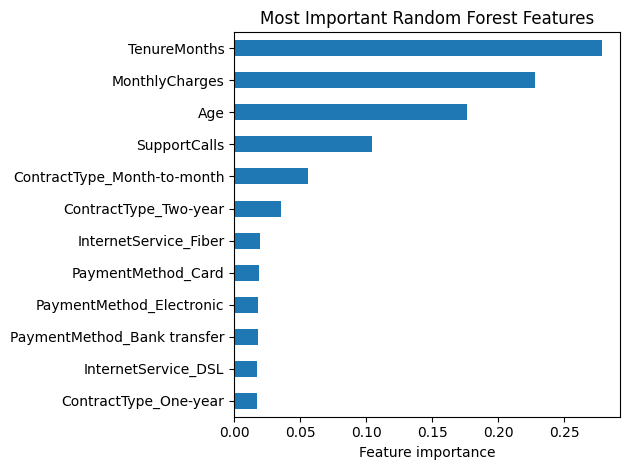

Random Forest accuracy: 0.762


In [8]:
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values().tail(12)
importances.plot(kind="barh")
plt.title("Most Important Random Forest Features")
plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()
print("Random Forest accuracy:", round(accuracy_score(y_test, rf_pred), 3))


## 5. K-Means clustering and PCA

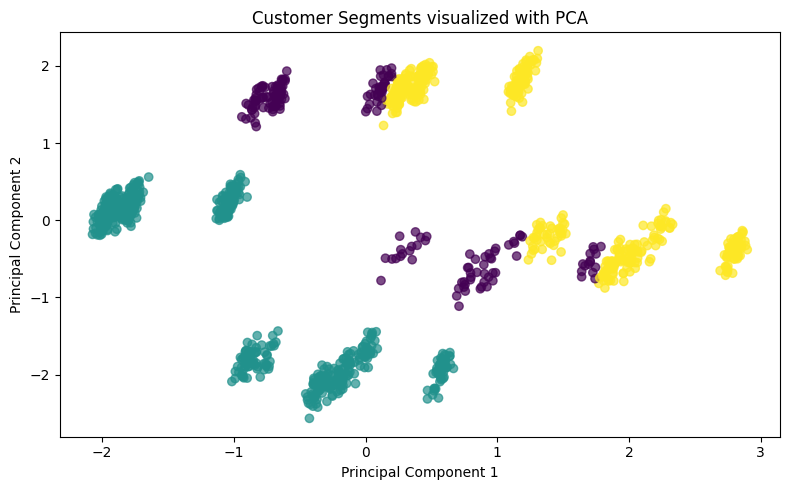

,Customers,AverageTenure,AverageMonthlyCharges,ChurnRate
Segment,,,,
0,181,36.96,68.10,0.70
1,586,36.38,67.69,0.66
2,433,37.37,70.94,0.65


PCA explained variance: [0.139 0.135]


In [9]:
# Standardize before clustering so high-scale columns do not dominate.
cluster_scaler = StandardScaler()
X_scaled = cluster_scaler.fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, alpha=0.7)
plt.title("Customer Segments visualized with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

segment_summary = df.assign(Segment=clusters).groupby("Segment").agg(
    Customers=("Churn", "size"),
    AverageTenure=("TenureMonths", "mean"),
    AverageMonthlyCharges=("MonthlyCharges", "mean"),
    ChurnRate=("Churn", "mean")
).round(2)
display(segment_summary)
print("PCA explained variance:", np.round(pca.explained_variance_ratio_, 3))


## 6. Feedforward Neural Network (FNN) and CNN

In [10]:
# TensorFlow is optional. Install with: %pip install tensorflow
try:
    import tensorflow as tf
    from tensorflow.keras import layers, models
    TF_AVAILABLE = True
    print("TensorFlow version:", tf.__version__)
except Exception as exc:
    TF_AVAILABLE = False
    print("TensorFlow is unavailable; neural-network cells are skipped.")
    print("If needed, install TensorFlow in a compatible Python environment:", exc)


TensorFlow version: 2.21.0


FNN test accuracy: 0.733


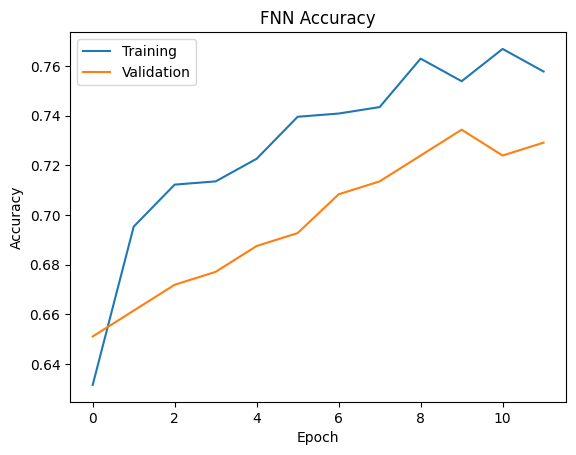

In [11]:
if TF_AVAILABLE:
    nn_scaler = StandardScaler()
    Xtr = nn_scaler.fit_transform(X_train).astype("float32")
    Xte = nn_scaler.transform(X_test).astype("float32")
    ytr = y_train.to_numpy().astype("float32")
    yte = y_test.to_numpy().astype("float32")

    fnn = models.Sequential([
        layers.Input(shape=(Xtr.shape[1],)),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])
    fnn.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    fnn_history = fnn.fit(Xtr, ytr, epochs=12, batch_size=32, validation_split=0.2, verbose=0)
    fnn_loss, fnn_acc = fnn.evaluate(Xte, yte, verbose=0)
    print("FNN test accuracy:", round(float(fnn_acc), 3))
    plt.plot(fnn_history.history["accuracy"], label="Training")
    plt.plot(fnn_history.history["val_accuracy"], label="Validation")
    plt.title("FNN Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()
else:
    print("Skipped: install TensorFlow to run the FNN.")


In [12]:
# CNN demonstration: reshape each row into a one-dimensional feature sequence.
# This is an educational baseline; tabular data usually suits FNN/tree models better.
if TF_AVAILABLE:
    Xtr_cnn = Xtr.reshape((Xtr.shape[0], Xtr.shape[1], 1))
    Xte_cnn = Xte.reshape((Xte.shape[0], Xte.shape[1], 1))
    cnn = models.Sequential([
        layers.Input(shape=(Xtr.shape[1], 1)),
        layers.Conv1D(16, kernel_size=3, activation="relu", padding="same"),
        layers.MaxPooling1D(pool_size=2),
        layers.Flatten(),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])
    cnn.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    cnn.fit(Xtr_cnn, ytr, epochs=8, batch_size=32, validation_split=0.2, verbose=0)
    _, cnn_acc = cnn.evaluate(Xte_cnn, yte, verbose=0)
    print("CNN demonstration test accuracy:", round(float(cnn_acc), 3))
else:
    print("Skipped: install TensorFlow to run the CNN.")


CNN demonstration test accuracy: 0.717


## 7. Generative Adversarial Network (GAN) demonstration

This section trains a small GAN to generate **standardized synthetic feature vectors**. These generated rows are for demonstrating the GAN concept only; they are not real customer records and should not be used to make customer decisions. GAN training may be unstable and needs more tuning for meaningful synthetic data.

In [13]:
if TF_AVAILABLE:
    # Use a small subset of standardized numerical feature vectors for a quick demo.
    gan_scaler = StandardScaler()
    real_data = gan_scaler.fit_transform(X).astype("float32")
    real_data = np.clip(real_data, -3, 3)
    feature_dim = real_data.shape[1]
    latent_dim = 16

    generator = models.Sequential([
        layers.Input(shape=(latent_dim,)),
        layers.Dense(32, activation="relu"),
        layers.Dense(feature_dim, activation="tanh")
    ], name="generator")

    discriminator = models.Sequential([
        layers.Input(shape=(feature_dim,)),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ], name="discriminator")
    discriminator.compile(optimizer="adam", loss="binary_crossentropy")

    discriminator.trainable = False
    gan_input = layers.Input(shape=(latent_dim,))
    gan_output = discriminator(generator(gan_input))
    gan = models.Model(gan_input, gan_output)
    gan.compile(optimizer="adam", loss="binary_crossentropy")
    discriminator.trainable = True

    batch_size = 32
    for epoch in range(150):
        ids = np.random.randint(0, len(real_data), batch_size)
        real_batch = real_data[ids]
        noise = np.random.normal(0, 1, (batch_size, latent_dim)).astype("float32")
        fake_batch = generator.predict(noise, verbose=0)
        discriminator.train_on_batch(real_batch, np.ones((batch_size, 1)))
        discriminator.train_on_batch(fake_batch, np.zeros((batch_size, 1)))
        noise = np.random.normal(0, 1, (batch_size, latent_dim)).astype("float32")
        gan.train_on_batch(noise, np.ones((batch_size, 1)))

    generated_scaled = generator.predict(np.random.normal(0, 1, (5, latent_dim)), verbose=0)
    print("Generated standardized feature vectors:", generated_scaled.shape)
    display(pd.DataFrame(generated_scaled, columns=X.columns).round(2))
else:
    print("Skipped: install TensorFlow to run the GAN.")


Generated standardized feature vectors: (5, 13)


,TenureMonths,MonthlyCharges,SupportCalls,Age,ContractType_Month-to-month,ContractType_One-year,ContractType_Two-year,InternetService_DSL,InternetService_Fiber,InternetService_None,PaymentMethod_Bank transfer,PaymentMethod_Card,PaymentMethod_Electronic
0,-0.80,-0.98,0.77,-0.51,0.15,-0.98,0.01,-0.81,0.36,-0.10,0.84,-0.49,-0.68
1,-0.70,-0.97,0.96,0.28,0.64,-0.95,0.27,-0.84,-0.95,0.94,0.91,-0.91,-0.92
2,-0.61,-0.67,0.30,-0.04,0.95,-0.75,0.44,-0.83,0.01,0.76,-0.19,-0.04,-0.86
3,-0.95,-0.85,0.86,-0.19,-0.08,-0.16,0.09,-0.62,-0.69,0.39,0.74,0.42,-0.83
4,-0.94,-0.64,0.12,0.89,0.97,-0.80,0.45,-0.83,-0.53,0.35,0.08,-0.56,-0.66


## 8. Model evaluation, Grid Search, and Cross-Validation

In [14]:
# Tune SVM parameters using a pipeline so scaling happens inside each CV fold.
svm_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())
])
param_grid = {
    "model__C": [0.1, 1, 10],
    "model__kernel": ["linear", "rbf"],
    "model__gamma": ["scale", "auto"]
}
grid = GridSearchCV(
    svm_pipe, param_grid, cv=5, scoring="f1", n_jobs=-1, refit=True
)
grid.fit(X_train, y_train)
best_model = grid.best_estimator_
best_pred = best_model.predict(X_test)
print("Best parameters:", grid.best_params_)
print("Best mean CV F1:", round(grid.best_score_, 3))
print("Held-out test accuracy:", round(accuracy_score(y_test, best_pred), 3))
print("Held-out test F1:", round(f1_score(y_test, best_pred, zero_division=0), 3))
print(classification_report(y_test, best_pred, zero_division=0))

cv_scores = cross_val_score(best_model, X_train, y_train, cv=5, scoring="f1")
print("Cross-validation F1 scores:", np.round(cv_scores, 3))
print("Mean CV F1:", round(cv_scores.mean(), 3))


Best parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best mean CV F1: 0.826
Held-out test accuracy: 0.742
Held-out test F1: 0.822
              precision    recall  f1-score   support

           0       0.67      0.44      0.53        80
           1       0.76      0.89      0.82       160

    accuracy                           0.74       240
   macro avg       0.72      0.67      0.68       240
weighted avg       0.73      0.74      0.72       240

Cross-validation F1 scores: [0.826 0.818 0.826 0.845 0.818]
Mean CV F1: 0.826


## 9. Save the model and prepare a Flask REST API

In [15]:
# Save the trained pipeline and exact feature order.
# The pipeline contains its own scaler.
joblib.dump(best_model, "artifacts/churn_model.joblib")
joblib.dump(list(X.columns), "artifacts/feature_columns.joblib")
print("Saved model and feature columns in the artifacts/ folder.")


Saved model and feature columns in the artifacts/ folder.


In [16]:
# Write a Flask app that accepts JSON feature values and returns a prediction.
# Start it from a terminal after running the notebook: python app.py
app_source = r'''
from flask import Flask, request, jsonify
import joblib
import pandas as pd

app = Flask(__name__)
model = joblib.load("artifacts/churn_model.joblib")
feature_columns = joblib.load("artifacts/feature_columns.joblib")

@app.get("/")
def home():
    return jsonify({
        "message": "Customer Churn Prediction API",
        "usage": "POST JSON feature values to /predict"
    })

@app.post("/predict")
def predict():
    payload = request.get_json(silent=True)
    if not isinstance(payload, dict):
        return jsonify({"error": "Send a JSON object containing feature values."}), 400
    try:
        row = pd.DataFrame([payload])
        row = row.reindex(columns=feature_columns, fill_value=0)
        prediction = int(model.predict(row)[0])
        result = {"prediction": prediction, "label": "Churn" if prediction == 1 else "Stay"}
        if hasattr(model, "predict_proba"):
            result["churn_probability"] = round(float(model.predict_proba(row)[0][1]), 4)
        return jsonify(result)
    except Exception as exc:
        return jsonify({"error": str(exc)}), 400

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000, debug=False)
'''
with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_source)
print("Created app.py")
print("Run in a terminal: python app.py")
print("Then open: http://127.0.0.1:5000")


Created app.py
Run in a terminal: python app.py
Then open: http://127.0.0.1:5000


### Test the REST API

In [17]:
# Optional: run this only after starting `python app.py` in another terminal.
# The input keys must match the encoded feature columns printed in X.columns.
# Example request template:
# import requests
# sample = X_test.iloc[0].to_dict()
# response = requests.post("http://127.0.0.1:5000/predict", json=sample, timeout=10)
# print(response.status_code, response.json())


## 10. Docker containerization

In [18]:
dockerfile = '''FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app.py .
COPY artifacts ./artifacts
EXPOSE 5000
CMD ["python", "app.py"]
'''
requirements = '''flask
pandas
scikit-learn
joblib
numpy
'''
with open("Dockerfile", "w", encoding="utf-8") as f:
    f.write(dockerfile)
with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements)

print("Created Dockerfile and requirements.txt")
print("Build:  docker build -t churn-api .")
print("Run:    docker run --rm -p 5000:5000 churn-api")


Created Dockerfile and requirements.txt
Build:  docker build -t churn-api .
Run:    docker run --rm -p 5000:5000 churn-api


## Conclusion

This project demonstrates a complete machine-learning workflow: data preparation, binary and multiclass classification, Decision Tree, SVM, Random Forest, K-Means clustering, PCA, FNN/CNN, a basic GAN, hyperparameter tuning, cross-validation, model saving, Flask API creation, and Docker packaging.

**Important:** The notebook uses generated demonstration data. Report actual scores from your run, do not claim a guaranteed accuracy, and do not use this model for real business decisions without testing it on representative, consented, real-world data.

